# Stranded coil, circuit equation and saturating iron (2D axisymmetric)

This notebook follows `docs/tutorials/data/coil_2D_avoltemf_ferr`: a 1000-turn **stranded coil** fed by a voltage source, a passive
copper ring above it, and a rectangular iron frame around both, described by a **B-H curve**. It shows:

* the circuit unknowns of a stranded coil, `VOLT` (terminal voltage) and `EMF` (induced voltage), and how to read the
  coil current from them, `i = (VOLT - EMF) / R`;
* a voltage-driven transient: the step response of an inductive circuit, `i(t) -> V / R` with the time constant
  `L / R`;
* the effect of the iron: a larger inductance, then saturation, which a nonlinear law handles with Newton's method;
* the report of the operating range of the B-H law at every step.

We run the same model twice, without and with the iron, and compare. Requirements: the `pytec3d` environment with
`pip install -e ".[notebooks]"` (pyvista, matplotlib). See the user manual (*Element Library: stranded coil*,
*Nonlinear Materials*) and the theory (*Stranded coils*, *Newton-Raphson*).

In [1]:
import os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # warnings ("No loads" at every voltage-driven step...) stay in the job log

CASE = Path("data/coil_2D_avoltemf_ferr").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_coil_2D_avoltemf_ferr_"))
for name in ("coil_2D_avoltemf_ferr.vtu", "model_data.json"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

import contextlib, io
def quietly():
    """Keep the report tables that the solver prints (run provenance, run summary) out of the notebook: they are in
    the job log <model name>.log of the working folder."""
    return contextlib.redirect_stdout(io.StringIO())

working in a temporary folder: pytec3d_coil_2D_avoltemf_ferr_os3rfml9


## The model

Axisymmetric about the y axis (x = r): the coil (TYPE 23, `STRANDED_COIL`) at r = 0.5 m, z = -0.5 m, the passive ring
(TYPE 24, `SOLID_CONDUCTOR`: in 2D a massive conductor without terminal, a closed ring) at z = +0.5 m, and the iron
frame (TYPE 26). The coil real
constants are in CONSTANT 1:

In [2]:
import json
data = json.load(open("model_data.json"))
coil = data["constants"]["1"]
print(json.dumps(coil))
R, N = coil["resistance"], coil["turns"]
print(f"R = {R} Ohm, N = {N:.0f} turns: a 1500 V source drives {1500 / R:.0f} A, i.e. {1500 / R * N / 1e3:.0f} kA-turns")

{"thickness": 1.0, "cross_section": 0.04, "turns": 1000.0, "radius": 0.5, "resistance": 50.0, "symmetry": 1.0, "T": [0.0, 0.0, 1.0]}
R = 50.0 Ohm, N = 1000 turns: a 1500 V source drives 30 A, i.e. 30 kA-turns


## One function for the whole analysis

`run(with_iron)` builds the analysis as the test macro does, then applies a 1500 V step at t = 0 and follows it for
1 s with backward Euler (100 steps of 10 ms):

1. read the mesh and the model data;
2. the iron frame: either TYPE / MATERIAL 26 with the B-H curve, or air (TYPE / MATERIAL 21);
3. A_z = 0 on the external boundary;
4. the coil terminal: `CP_0 = 1` on the coil nodes, coupling `["EMF", "VOLT"]` (model data `dof_couplings["1"]`);
5. the passive ring: nothing to set (a 2D solid conductor has no electric unknown);
6. load the model, then the steps with `_VOLT = 1500` on the coil master node.

After each step it records the terminal quantities at the master node, the coil current, the Newton iterations and
the largest |B| in the iron (the *law range* of the step report). The report tables of each run go to its log file
(`air.log`, `iron.log`), not to the notebook.

In [3]:
BH = np.array([[0.0, 0.0], [100.0, 0.372], [200.0, 0.744], [255.0, 0.936], [299.1, 1.102], [373.2, 1.287],
               [447.5, 1.415], [521.3, 1.488], [595.2, 1.553], [743.3, 1.641], [1113.8, 1.763], [1484.7, 1.838],
               [1855.2, 1.879], [2226.9, 1.922], [3661.0, 1.998], [5870.7, 2.092], [10289.3, 2.220],
               [20396.8, 2.435]])                                       # rows [H (A/m), B (T)]

def run(with_iron, volt=1500.0, dt=1e-2, steps=100):
    with contextlib.redirect_stdout(io.StringIO()):     # the report tables go to the log file only
        return _run(with_iron, volt, dt, steps)   # (quietly() of the setup cell does the same)

def _run(with_iron, volt, dt, steps):
    solver = Solver(log_file="iron.log" if with_iron else "air.log")
    solver.read_model("coil_2D_avoltemf_ferr.vtu")
    solver.model.read_json("model_data.json")
    mesh = solver.model.mesh

    # 2. iron frame (the mesh already has TYPE 26 on it) or air
    selection.select(mesh, "TYPE", 26, location="elem")
    if with_iron:
        solver.model.set_bh_curve(26, BH)
    else:
        selection.set_value_on_selection(mesh, "TYPE", 21, location="elem")
        selection.set_value_on_selection(mesh, "MATERIAL", 21, location="elem")

    # 3. A_z = 0 on the external boundary
    selection.select_all(mesh); selection.nsel_ext(mesh)
    selection.set_value_on_selection(mesh, "_A", 0.0, 2)

    # 4. coil terminal (5. the passive ring is a solid conductor: nothing to set)
    selection.select(mesh, "MATERIAL", 23, location="elem"); selection.nsle(mesh)
    selection.set_value_on_selection(mesh, "CP_0", 1)
    master = int(selection.selected_ids(mesh, "node")[0])

    # 6. load, then the voltage step
    solver.load_model_into_solver()
    solver.time_step["theta"] = 1.0
    selection.select(mesh, "ID", master)
    selection.set_value_on_selection(mesh, "_VOLT", volt)
    rows = []
    for n in range(1, steps + 1):
        solver.time_step["time"] = n * dt
        solver.solve()
        v = float(meshes.array_values(mesh, "VOLT", "node")[master])
        e = float(meshes.array_values(mesh, "EMF", "node")[master])
        report = solver.steps[-1]["report"]
        b_iron = max([r["max_input"] for r in report["law_ranges"]], default=0.0)
        rows.append((n * dt, v, e, (v - e) / R, solver.steps[-1]["newton_iterations"], b_iron))
    if with_iron:
        solver.write_output()          # keep the last state for the plots below
    grid = pv.wrap(mesh).copy()
    solver.close()
    return np.array(rows), grid

air, _ = run(with_iron=False)
iron, grid = run(with_iron=True)
print("final coil current: air %.2f A, iron %.2f A (V / R = %.0f A)" % (air[-1, 3], iron[-1, 3], 1500 / R))
print("Newton iterations per step (iron): min %d, max %d" % (iron[:, 4].min(), iron[:, 4].max()))

final coil current: air 30.00 A, iron 27.72 A (V / R = 30 A)
Newton iterations per step (iron): min 1, max 3


## Step response

In air the current rises with a single time constant `L / R` (about 20 ms here). The iron frame guides the flux and
multiplies the inductance: the rise is an order of magnitude slower. The EMF is the voltage induced in the winding by
the change of the linked flux, `EMF = dPsi/dt`; it starts close to the source voltage and decays as the current
settles, `i = (VOLT - EMF) / R`. In the last part of the transient the iron reaches the knee of its B-H curve: its
differential permeability, and the inductance seen by the source, decrease, and Newton needs more than one iteration
per step (in the linear first segment of the curve one iteration is exact).

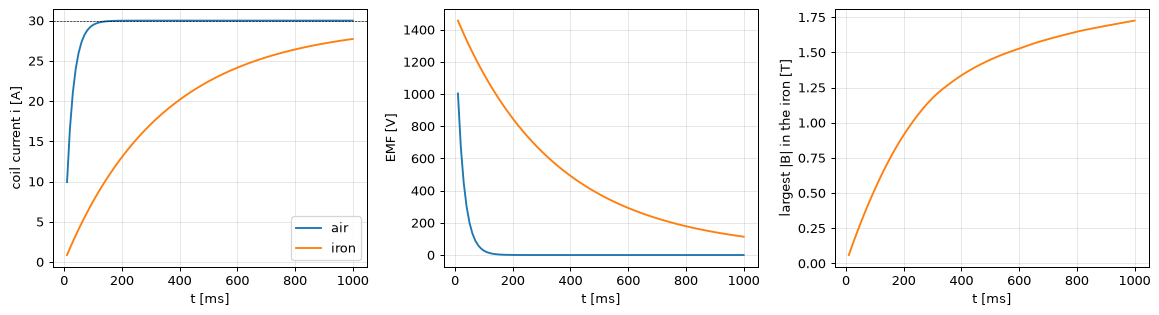

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for data, label in ((air, "air"), (iron, "iron")):
    ax[0].plot(data[:, 0] * 1e3, data[:, 3], label=label)
    ax[1].plot(data[:, 0] * 1e3, data[:, 2], label=label)
ax[0].axhline(1500 / R, color="k", lw=0.5, ls="--"); ax[0].set_ylabel("coil current i [A]")
ax[1].set_ylabel("EMF [V]")
ax[2].plot(iron[:, 0] * 1e3, iron[:, 5], "C1"); ax[2].set_ylabel("largest |B| in the iron [T]")
for a in ax:
    a.set_xlabel("t [ms]"); a.grid(alpha=0.3)
ax[0].legend(); plt.tight_layout(); plt.show()

## Where the iron works on its B-H curve

The law `bh_curve` uses the table as a piecewise-linear curve, extended along its last segment. The largest |B| of
each step (the element mean, as reported by the solver) shows how far into saturation the frame goes.

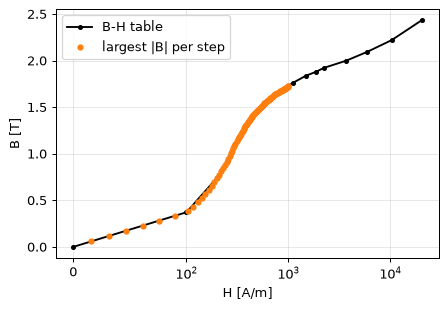

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(BH[:, 0], BH[:, 1], "k.-", label="B-H table")
h_op = np.interp(iron[:, 5], BH[:, 1], BH[:, 0])
ax.plot(h_op, iron[:, 5], "o", color="C1", ms=4, label="largest |B| per step")
ax.set_xscale("symlog", linthresh=100); ax.set_xlabel("H [A/m]"); ax.set_ylabel("B [T]"); ax.grid(alpha=0.3)
ax.legend(); plt.show()

## The field at the end of the transient

The flux is guided by the frame; the colour shows |B| on the nodes, the arrows the in-plane B.

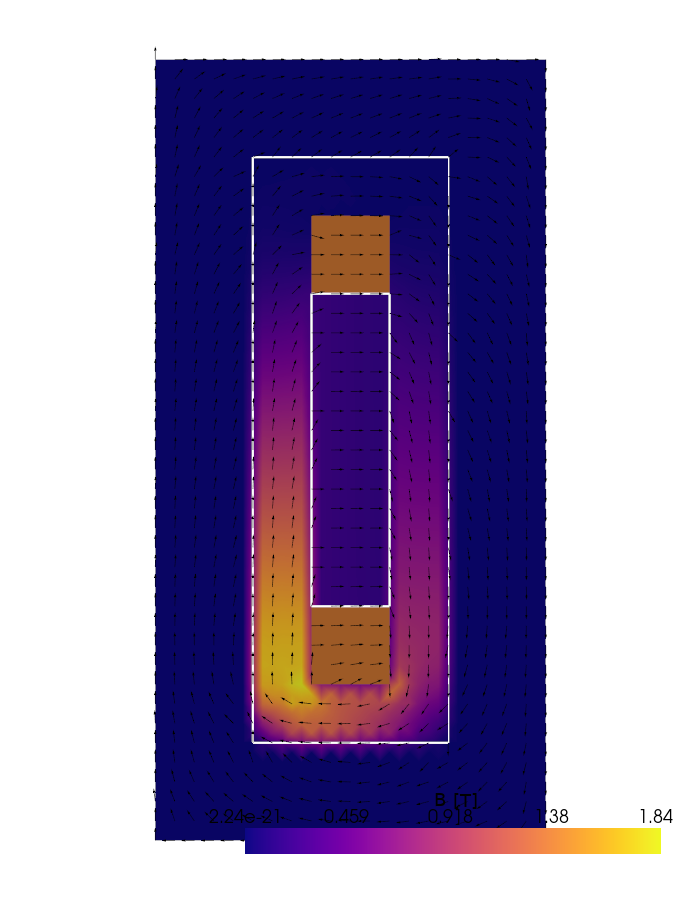

In [6]:
grid.point_data["|B|"] = np.linalg.norm(grid.point_data["B"], axis=1)
surface = grid.extract_surface(algorithm=None)
outline = surface.extract_feature_edges(boundary_edges=True, feature_edges=False, manifold_edges=False)
regions = grid.threshold(value=(22, 30), scalars="TYPE").extract_surface(algorithm=None).extract_feature_edges(
    boundary_edges=True, feature_edges=False, manifold_edges=False)
arrows = surface.glyph(orient="B", scale=False, factor=0.035, tolerance=0.02)

pl = pv.Plotter(window_size=(700, 900))
pl.add_mesh(surface, scalars="|B|", cmap="plasma", scalar_bar_args={"title": "|B| [T]"})
pl.add_mesh(grid.threshold(value=(23, 24), scalars="TYPE").extract_surface(algorithm=None), color="#c87533")
pl.add_mesh(regions, color="white", line_width=2)
pl.add_mesh(arrows, color="black")
pl.view_xy(); pl.camera.zoom(1.3)
pl.show()

## Try it yourself

* Halve the source voltage: the iron saturates less and the two curves get closer.
* Drive the coil by its current instead (`CURR` on the master node, `_VOLT` free): the EMF is then the only output of
  the circuit, and `VOLT = R i + EMF` gives the voltage the source must supply.
* Use the time-integrated element type (`"element_type": "AV2D_nodal_timint"` in the model data): `VOLT` and `EMF`
  become the time integrals of the voltages; `_VOLT` must then be a ramp `V t`.